# 1 — 掛載雲端硬碟 & 設定路徑

In [1]:
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = "/content/drive/MyDrive/Colab Notebooks/ML_final_project"
DATA_DIR     = f"{PROJECT_ROOT}/data"
MODEL_DIR    = f"{PROJECT_ROOT}/models"

print("DATA_DIR:", DATA_DIR)
print("MODEL_DIR:", MODEL_DIR)


Mounted at /content/drive
DATA_DIR: /content/drive/MyDrive/Colab Notebooks/ML_final_project/data
MODEL_DIR: /content/drive/MyDrive/Colab Notebooks/ML_final_project/models


# 2 — Import 套件

In [2]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

import matplotlib.pyplot as plt


# 3 — 設定 Hyperparameters

In [3]:
# ECG shape: (12, 1000) from preprocessing
N_CHANNELS = 12
N_TIME     = 1000
N_CLASSES  = 2

BATCH_SIZE = 64
NUM_EPOCHS = 30
LEARNING_RATE = 1e-3
WEIGHT_DECAY  = 1e-4

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


# 4 — DataLoader

In [4]:
class ECGDataset(Dataset):
    def __init__(self, X, y):
        self.X = X.astype(np.float32)
        self.y = y.astype(np.int64)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = self.X[idx]          # (12, T)
        y = self.y[idx]
        x = torch.tensor(x).unsqueeze(0)  # → (1, 12, T)
        return x, torch.tensor(y)


In [6]:
X_train = np.load(f"{DATA_DIR}/X_train.npy")
y_train = np.load(f"{DATA_DIR}/y_train.npy")
X_val   = np.load(f"{DATA_DIR}/X_val.npy")
y_val   = np.load(f"{DATA_DIR}/y_val.npy")

train_loader = DataLoader(ECGDataset(X_train, y_train),
                          batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

val_loader = DataLoader(ECGDataset(X_val, y_val),
                        batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("Train:", X_train.shape, y_train.shape)
print("Val:  ", X_val.shape,   y_val.shape)


Train: (17469, 12, 1000) (17469,)
Val:   (4368, 12, 1000) (4368,)


# 5 — SCCNet Model



In [7]:
class ECG_SCCNet(nn.Module):
    def __init__(self, n_channels=12, n_time=1000, n_classes=2, use_adaptive_pool=True):
        super().__init__()

        self.spatial_conv = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=(n_channels, 1), bias=False),
            nn.BatchNorm2d(32)
        )

        self.temporal_conv = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=(1, 25), padding=(0, 12), bias=False),
            nn.BatchNorm2d(64),
            nn.ELU(),
            nn.AvgPool2d(kernel_size=(1, 8)),
            nn.Dropout(0.5)
        )

        self.use_adaptive_pool = use_adaptive_pool
        if use_adaptive_pool:
            self.adaptive_pool = nn.AdaptiveAvgPool2d((1, 32))
            final_dim = 64 * 32
        else:
            self.adaptive_pool = nn.Identity()
            final_dim = 64 * (n_time // 8)

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(final_dim, n_classes)
        )

    def forward(self, x):
        out = self.spatial_conv(x)       # (B, 32, 1, T)
        out = self.temporal_conv(out)    # (B, 64, 1, T/8)
        out = self.adaptive_pool(out)    # (B, 64, 1, 32)
        out = self.classifier(out)
        return out

model = ECG_SCCNet().to(device)
print(model)


ECG_SCCNet(
  (spatial_conv): Sequential(
    (0): Conv2d(1, 32, kernel_size=(12, 1), stride=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (temporal_conv): Sequential(
    (0): Conv2d(32, 64, kernel_size=(1, 25), stride=(1, 1), padding=(0, 12), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ELU(alpha=1.0)
    (3): AvgPool2d(kernel_size=(1, 8), stride=(1, 8), padding=0)
    (4): Dropout(p=0.5, inplace=False)
  )
  (adaptive_pool): AdaptiveAvgPool2d(output_size=(1, 32))
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=2, bias=True)
  )
)


# 6 — Loss & Optimizer

In [8]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# 7 — Training & Validation Functions

In [9]:
def train_one_epoch(model, loader, optimizer, criterion):
    model.train()
    total_loss = 0
    preds_all, labels_all = [], []

    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()

        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)

        preds = logits.argmax(dim=1)
        preds_all.append(preds.cpu().numpy())
        labels_all.append(y.cpu().numpy())

    preds_all = np.concatenate(preds_all)
    labels_all = np.concatenate(labels_all)

    return (
        total_loss / len(loader.dataset),
        accuracy_score(labels_all, preds_all),
        f1_score(labels_all, preds_all, average="macro")
    )


def eval_one_epoch(model, loader, criterion):
    model.eval()
    total_loss = 0
    preds_all, labels_all, prob_all = [], [], []

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = criterion(logits, y)

            total_loss += loss.item() * x.size(0)

            probs = F.softmax(logits, dim=1)
            preds = probs.argmax(dim=1)

            preds_all.append(preds.cpu().numpy())
            labels_all.append(y.cpu().numpy())
            prob_all.append(probs.cpu().numpy())

    preds_all = np.concatenate(preds_all)
    labels_all = np.concatenate(labels_all)
    prob_all = np.concatenate(prob_all)

    try:
        auc = roc_auc_score(labels_all, prob_all[:, 1])
    except:
        auc = None

    return (
        total_loss / len(loader.dataset),
        accuracy_score(labels_all, preds_all),
        f1_score(labels_all, preds_all, average="macro"),
        auc
    )


# 8 — Training Loop

In [10]:
train_losses, val_losses = [], []
train_accs,  val_accs  = [], []
train_f1s,   val_f1s   = [], []
val_aucs = []

best_val_acc = 0
os.makedirs(MODEL_DIR, exist_ok=True)
save_path = f"{MODEL_DIR}/sccnet_best.pt"

for epoch in range(1, NUM_EPOCHS + 1):

    tr_loss, tr_acc, tr_f1 = train_one_epoch(model, train_loader, optimizer, criterion)
    va_loss, va_acc, va_f1, va_auc = eval_one_epoch(model, val_loader, criterion)

    train_losses.append(tr_loss)
    train_accs.append(tr_acc)
    train_f1s.append(tr_f1)

    val_losses.append(va_loss)
    val_accs.append(va_acc)
    val_f1s.append(va_f1)
    val_aucs.append(va_auc)

    print(f"[Epoch {epoch:02d}] "
          f"Train Loss {tr_loss:.4f} | Acc {tr_acc:.4f} | F1 {tr_f1:.4f} || "
          f"Val Loss {va_loss:.4f} | Acc {va_acc:.4f} | F1 {va_f1:.4f} | AUC {va_auc}")

    if va_acc > best_val_acc:
        best_val_acc = va_acc
        torch.save(model.state_dict(), save_path)
        print(" → New best model saved!")


[Epoch 01] Train Loss 0.5552 | Acc 0.7257 | F1 0.5503 || Val Loss 0.4674 | Acc 0.8267 | F1 0.6396 | AUC 0.8644799977375494
 → New best model saved!
[Epoch 02] Train Loss 0.4156 | Acc 0.8208 | F1 0.6436 || Val Loss 0.3763 | Acc 0.8178 | F1 0.6487 | AUC 0.9148203080075037
[Epoch 03] Train Loss 0.3704 | Acc 0.8475 | F1 0.6765 || Val Loss 0.3714 | Acc 0.8107 | F1 0.6468 | AUC 0.920824443264339
[Epoch 04] Train Loss 0.3444 | Acc 0.8587 | F1 0.6912 || Val Loss 0.3466 | Acc 0.8528 | F1 0.6888 | AUC 0.9279806214825963
 → New best model saved!
[Epoch 05] Train Loss 0.3407 | Acc 0.8563 | F1 0.6894 || Val Loss 0.3460 | Acc 0.9068 | F1 0.7496 | AUC 0.9336599222596852
 → New best model saved!
[Epoch 06] Train Loss 0.3295 | Acc 0.8647 | F1 0.6998 || Val Loss 0.3295 | Acc 0.8915 | F1 0.7328 | AUC 0.9352012166956281
[Epoch 07] Train Loss 0.3203 | Acc 0.8696 | F1 0.7063 || Val Loss 0.3379 | Acc 0.8716 | F1 0.7076 | AUC 0.9296982770810618
[Epoch 08] Train Loss 0.3091 | Acc 0.8752 | F1 0.7155 || Val Loss

# 9 — Learning Curves

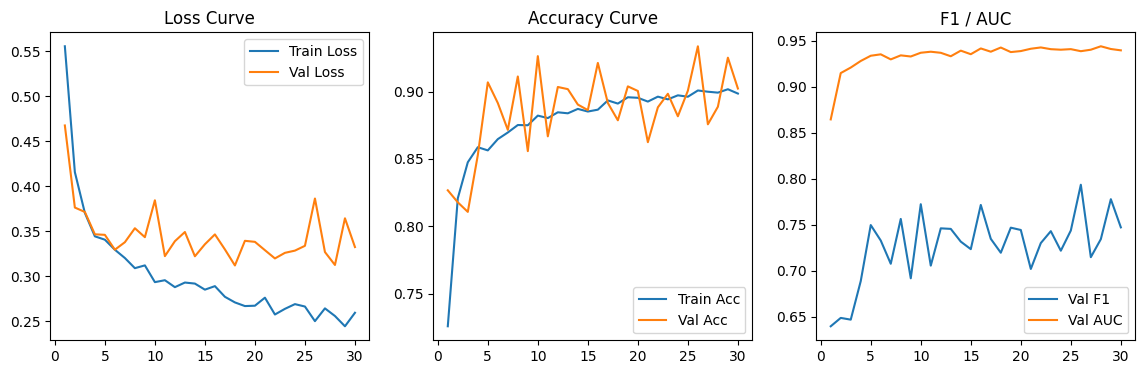

In [11]:
epochs = range(1, NUM_EPOCHS + 1)

plt.figure(figsize=(14,4))

plt.subplot(1,3,1)
plt.plot(epochs, train_losses, label="Train Loss")
plt.plot(epochs, val_losses, label="Val Loss")
plt.legend(); plt.title("Loss Curve")

plt.subplot(1,3,2)
plt.plot(epochs, train_accs, label="Train Acc")
plt.plot(epochs, val_accs, label="Val Acc")
plt.legend(); plt.title("Accuracy Curve")

plt.subplot(1,3,3)
plt.plot(epochs, val_f1s, label="Val F1")
plt.plot(epochs, val_aucs, label="Val AUC")
plt.legend(); plt.title("F1 / AUC")

plt.show()


# 10 — Confusion Matrix

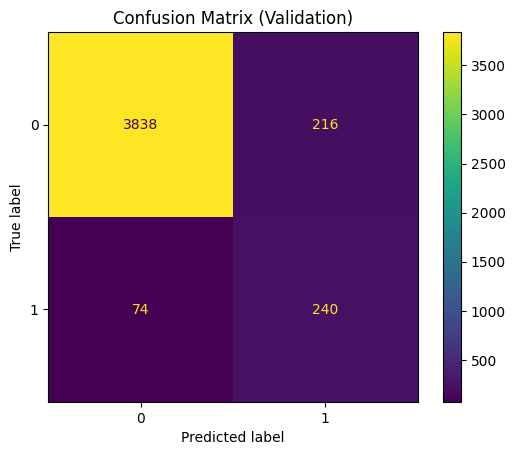

In [12]:
best_model = ECG_SCCNet().to(device)
best_model.load_state_dict(torch.load(save_path))
best_model.eval()

all_preds, all_labels = [], []

with torch.no_grad():
    for x, y in val_loader:
        x = x.to(device)
        logits = best_model(x)
        preds = logits.argmax(dim=1)

        all_preds.append(preds.cpu().numpy())
        all_labels.append(y.numpy())

all_preds  = np.concatenate(all_preds)
all_labels = np.concatenate(all_labels)

cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(cm)
disp.plot()
plt.title("Confusion Matrix (Validation)")
plt.show()
